# Entrenamiento local

Cada integrante del equipo entrena el modelo global (`CaffeLeNet.py`) con su partición privada de MNIST y entrega el modelo resultante al servidor. Este cuaderno contiene únicamente el ciclo de entrenamiento y la evaluación de cada modelo local: curvas de aprendizaje y *classification report*.

En un despliegue real, cada integrante ejecuta este cuaderno en su propia computadora con `CLIENT_IDS = [k]`. Para simular el flujo completo, se pueden entrenar todos los clientes en una sola ejecución.

In [1]:
import json
import os

import numpy as np
import tensorflow as tf
from matplotlib import pyplot as plt
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

from CaffeLeNet import build

### Configuración

- `DATA_DIR`: carpeta con las particiones privadas `client_{k}.npz` (no versionadas; ver `README.md`).
- `BATCH_SIZE = 64`: tamaño de lote del ejemplo de MNIST de Caffe.
- `VAL_SIZE`: fracción de los datos locales reservada para validación. Un cliente no tiene acceso a los datos de prueba del servidor, por lo que las curvas de aprendizaje usan validación local.
- `SHARED_INIT = True`: todos los clientes parten del mismo modelo inicial $w_0$, como si el servidor lo distribuyera antes del entrenamiento. FedAvg asume esta condición (McMahan et al., 2017).

In [2]:
DATA_DIR = "./private/data"
CLIENT_IDS = [0, 1, 2, 3]  # en un despliegue real: únicamente el id propio
EPOCHS = 5
BATCH_SIZE = 64
VAL_SIZE = 0.1
SEED = 42
SHARED_INIT = True

for folder in ("models", "reports", "viz"):
    os.makedirs(folder, exist_ok=True)

### Datos

El conjunto de prueba de MNIST es común a todos los clientes y solo se usa para el *classification report* final de cada modelo local.

In [3]:
def load_client(client_id):
    """Carga la partición privada de un cliente y escala los píxeles a [0, 1]."""
    with np.load(os.path.join(DATA_DIR, f"client_{client_id}.npz")) as data:
        x = np.expand_dims(data["x"] / 255.0, -1).astype("float32")
        y = data["y"]
    return x, y


_, (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_test = np.expand_dims(x_test / 255.0, -1).astype("float32")

### Ciclo de entrenamiento y evaluación

Para cada cliente se guardan:
- `models/lmodel_{k}.keras`: el modelo local entrenado.
- `models/lmodel_{k}.json`: el número de ejemplos de entrenamiento $n_k$, que el servidor usa para ponderar FedAvg.
- `reports/lmodel_{k}.txt`: el *classification report* sobre el conjunto de prueba.
- `viz/lmodel_{k}.png`: las curvas de aprendizaje (pérdida y exactitud).

In [4]:
def plot_learning_curves(history, name):
    epochs = range(1, len(history.history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric, label in zip(axes, ("loss", "accuracy"), ("Pérdida", "Exactitud")):
        ax.plot(epochs, history.history[metric], marker="o", label="Entrenamiento")
        ax.plot(epochs, history.history[f"val_{metric}"], marker="o", label="Validación")
        ax.set_xticks(list(epochs))
        ax.set_xlabel("Época")
        ax.set_ylabel(label)
        ax.legend()
    fig.suptitle(f"Curvas de aprendizaje: {name}")
    fig.tight_layout()
    fig.savefig(f"viz/{name}.png")
    plt.show()


def train_and_evaluate(client_id):
    name = f"lmodel_{client_id}"
    x, y = load_client(client_id)
    x_train, x_val, y_train, y_val = train_test_split(
        x, y, test_size=VAL_SIZE, stratify=y, random_state=SEED
    )

    # Con SHARED_INIT, la misma semilla produce el mismo w0 en todos los clientes.
    tf.keras.utils.set_random_seed(SEED if SHARED_INIT else SEED + client_id + 1)
    model = build.build_it(name=name)

    history = model.fit(
        x_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(x_val, y_val),
        verbose=2,
    )

    y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
    report = classification_report(y_test, y_pred, digits=4)
    print(f"Classification report de {name} (conjunto de prueba):\n{report}")
    with open(f"reports/{name}.txt", "w", encoding="utf-8") as f:
        f.write(report)

    plot_learning_curves(history, name)

    model.save(f"models/{name}.keras")
    with open(f"models/{name}.json", "w", encoding="utf-8") as f:
        json.dump({"client_id": client_id, "n_samples": len(y_train)}, f)

Epoch 1/5
211/211 - 4s - 20ms/step - accuracy: 0.8556 - loss: 0.4692 - val_accuracy: 0.9567 - val_loss: 0.1573
Epoch 2/5
211/211 - 2s - 12ms/step - accuracy: 0.9653 - loss: 0.1184 - val_accuracy: 0.9740 - val_loss: 0.0928
Epoch 3/5
211/211 - 3s - 12ms/step - accuracy: 0.9791 - loss: 0.0713 - val_accuracy: 0.9773 - val_loss: 0.0814
Epoch 4/5
211/211 - 2s - 11ms/step - accuracy: 0.9860 - loss: 0.0484 - val_accuracy: 0.9753 - val_loss: 0.0817
Epoch 5/5
211/211 - 2s - 11ms/step - accuracy: 0.9922 - loss: 0.0309 - val_accuracy: 0.9800 - val_loss: 0.0674
Classification report de lmodel_0 (conjunto de prueba):
              precision    recall  f1-score   support

           0     0.9663    0.9939    0.9799       980
           1     0.9912    0.9938    0.9925      1135
           2     0.9815    0.9777    0.9796      1032
           3     0.9744    0.9812    0.9778      1010
           4     0.9938    0.9807    0.9872       982
           5     0.9854    0.9832    0.9843       892
          

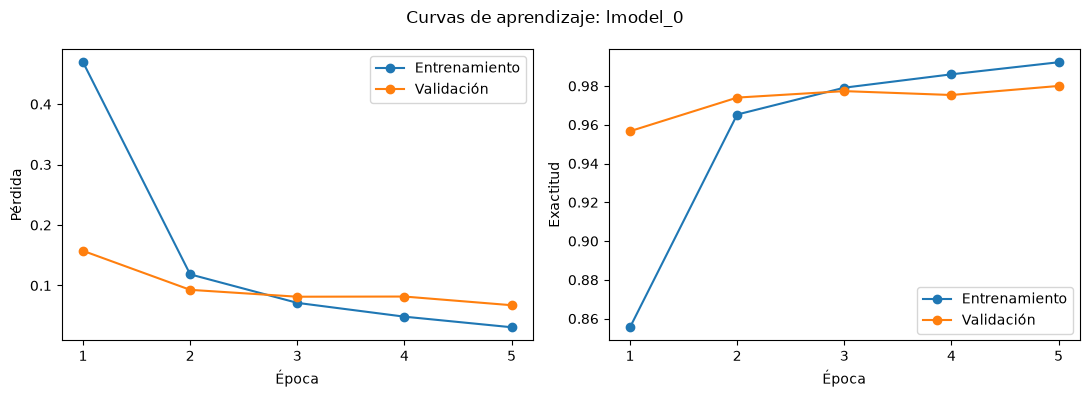

Epoch 1/5
211/211 - 3s - 16ms/step - accuracy: 0.8556 - loss: 0.4733 - val_accuracy: 0.9507 - val_loss: 0.1617
Epoch 2/5
211/211 - 2s - 11ms/step - accuracy: 0.9624 - loss: 0.1196 - val_accuracy: 0.9660 - val_loss: 0.1008
Epoch 3/5
211/211 - 3s - 12ms/step - accuracy: 0.9779 - loss: 0.0734 - val_accuracy: 0.9707 - val_loss: 0.0869
Epoch 4/5
211/211 - 2s - 11ms/step - accuracy: 0.9844 - loss: 0.0492 - val_accuracy: 0.9727 - val_loss: 0.0873
Epoch 5/5
211/211 - 2s - 11ms/step - accuracy: 0.9912 - loss: 0.0332 - val_accuracy: 0.9707 - val_loss: 0.0860
Classification report de lmodel_1 (conjunto de prueba):
              precision    recall  f1-score   support

           0     0.9877    0.9806    0.9841       980
           1     0.9946    0.9753    0.9849      1135
           2     0.9663    0.9719    0.9691      1032
           3     0.9505    0.9891    0.9694      1010
           4     0.9938    0.9735    0.9835       982
           5     0.9874    0.9686    0.9779       892
          

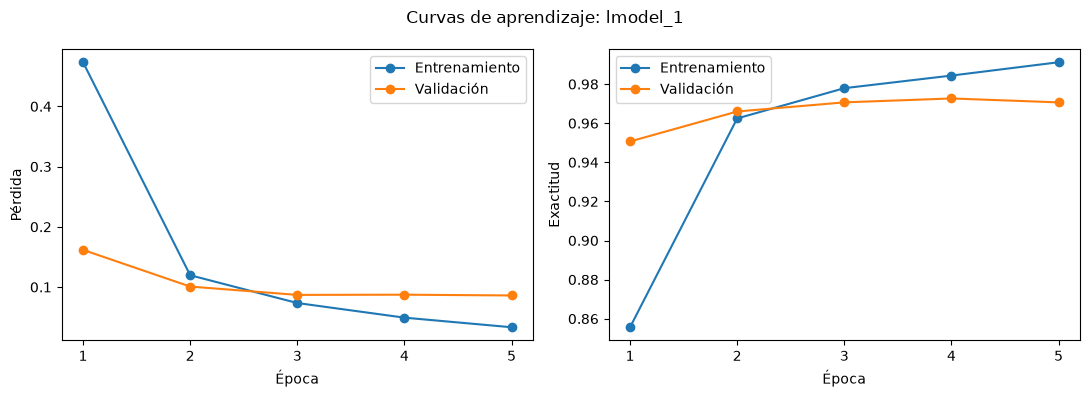

Epoch 1/5
211/211 - 4s - 17ms/step - accuracy: 0.8600 - loss: 0.4701 - val_accuracy: 0.9380 - val_loss: 0.1766
Epoch 2/5
211/211 - 2s - 11ms/step - accuracy: 0.9647 - loss: 0.1188 - val_accuracy: 0.9647 - val_loss: 0.1051
Epoch 3/5
211/211 - 2s - 12ms/step - accuracy: 0.9796 - loss: 0.0692 - val_accuracy: 0.9687 - val_loss: 0.0837
Epoch 4/5
211/211 - 2s - 11ms/step - accuracy: 0.9873 - loss: 0.0456 - val_accuracy: 0.9773 - val_loss: 0.0720
Epoch 5/5
211/211 - 2s - 12ms/step - accuracy: 0.9925 - loss: 0.0293 - val_accuracy: 0.9787 - val_loss: 0.0655
Classification report de lmodel_2 (conjunto de prueba):
              precision    recall  f1-score   support

           0     0.9838    0.9888    0.9863       980
           1     0.9767    0.9991    0.9878      1135
           2     0.9778    0.9826    0.9802      1032
           3     0.9841    0.9822    0.9832      1010
           4     0.9837    0.9857    0.9847       982
           5     0.9821    0.9854    0.9838       892
          

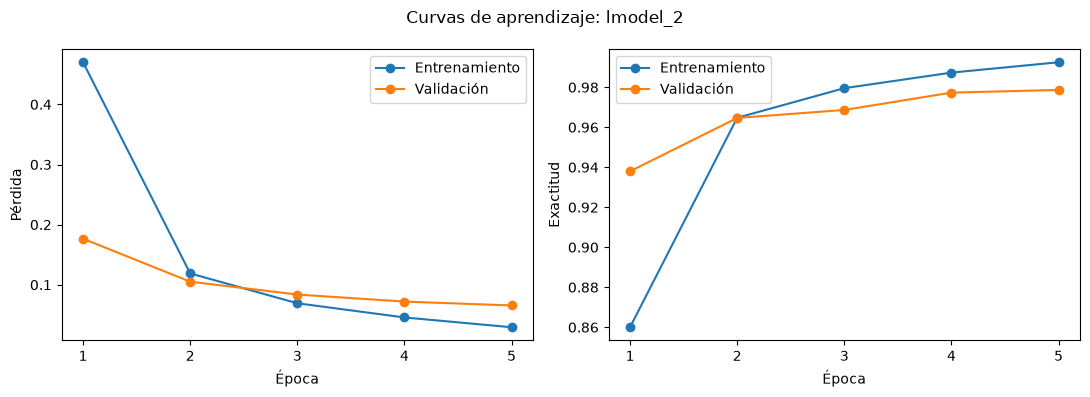

Epoch 1/5
211/211 - 3s - 16ms/step - accuracy: 0.8621 - loss: 0.4683 - val_accuracy: 0.9460 - val_loss: 0.1694
Epoch 2/5
211/211 - 2s - 11ms/step - accuracy: 0.9627 - loss: 0.1252 - val_accuracy: 0.9640 - val_loss: 0.1225
Epoch 3/5
211/211 - 2s - 12ms/step - accuracy: 0.9776 - loss: 0.0746 - val_accuracy: 0.9653 - val_loss: 0.1110
Epoch 4/5
211/211 - 3s - 13ms/step - accuracy: 0.9867 - loss: 0.0487 - val_accuracy: 0.9753 - val_loss: 0.0949
Epoch 5/5
211/211 - 3s - 13ms/step - accuracy: 0.9912 - loss: 0.0322 - val_accuracy: 0.9773 - val_loss: 0.0855
Classification report de lmodel_3 (conjunto de prueba):
              precision    recall  f1-score   support

           0     0.9720    0.9918    0.9818       980
           1     0.9869    0.9974    0.9921      1135
           2     0.9750    0.9816    0.9783      1032
           3     0.9832    0.9832    0.9832      1010
           4     0.9748    0.9868    0.9808       982
           5     0.9786    0.9742    0.9764       892
          

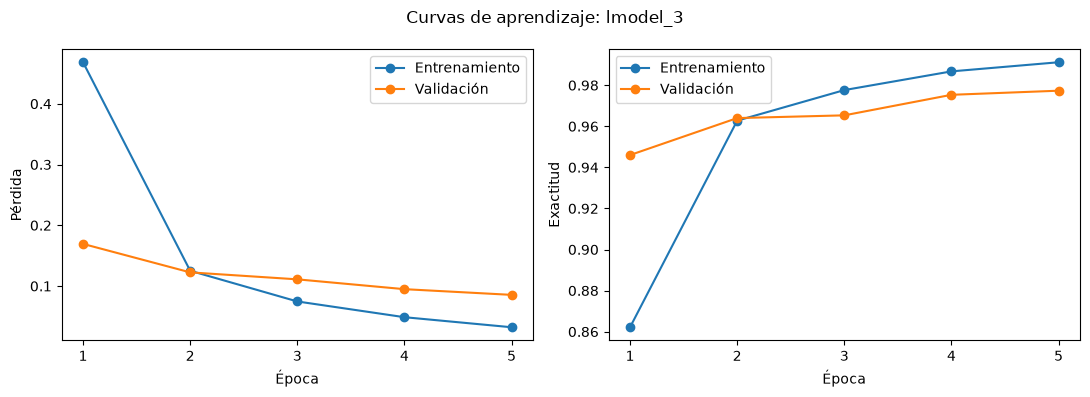

In [5]:
for client_id in CLIENT_IDS:
    train_and_evaluate(client_id)